# Projeto SETA - Classificador Supervisionado
### Classificação de tipos de cobertura florestal (Forest Covertype)

**Integrantes:**

- Arthur Falcão Pimentel Pereira (matrícula 17252432)
- Edson Guilherme Castiliano dos Santos (matrícula 18252060)
- Iraquitan Vereda dos Santos (matrícula 18251042)
- Mayara Evelly Duarte de Lima Santos (matrícula 18242026)

**Base de dados:** Forest Covertype (UCI Machine Learning Repository, carregada pelo scikit-learn)

**Objetivo:** treinar e comparar classificadores que descobrem o tipo de cobertura florestal de uma área de 30 x 30 metros a partir de características do terreno (altitude, inclinação, distâncias, tipo de solo e área silvestre). A comparação usa a mesma divisão treino/teste e as mesmas métricas para todos os modelos. Também verificamos se houve overfitting ou underfitting e testamos a redução de dimensionalidade com PCA.

## 1. Configuração das bibliotecas

In [1]:
import time
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, learning_curve, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

# Mostra todas as colunas das tabelas, sem cortar
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

# Número fixo para o sorteio dar sempre o mesmo resultado (reprodutibilidade)
SEED = 42

# Profundidade máxima das árvores (limita o quanto o modelo decora o treino)
PROFUNDIDADE_ARVORE = 18
PROFUNDIDADE_FLORESTA = 15

## 2. Carregamento da base

A base é baixada direto pelo scikit-learn. No primeiro uso ela é baixada da internet e depois fica guardada no computador.

In [2]:
dados = fetch_covtype(as_frame=True)
df = dados.frame
df.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area_0,Wilderness_Area_1,Wilderness_Area_2,Wilderness_Area_3,Soil_Type_0,Soil_Type_1,Soil_Type_2,Soil_Type_3,Soil_Type_4,Soil_Type_5,Soil_Type_6,Soil_Type_7,Soil_Type_8,Soil_Type_9,Soil_Type_10,Soil_Type_11,Soil_Type_12,Soil_Type_13,Soil_Type_14,Soil_Type_15,Soil_Type_16,Soil_Type_17,Soil_Type_18,Soil_Type_19,Soil_Type_20,Soil_Type_21,Soil_Type_22,Soil_Type_23,Soil_Type_24,Soil_Type_25,Soil_Type_26,Soil_Type_27,Soil_Type_28,Soil_Type_29,Soil_Type_30,Soil_Type_31,Soil_Type_32,Soil_Type_33,Soil_Type_34,Soil_Type_35,Soil_Type_36,Soil_Type_37,Soil_Type_38,Soil_Type_39,Cover_Type
0,2596.0,51.0,3.0,258.0,0.0,510.0,221.0,232.0,148.0,6279.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5
1,2590.0,56.0,2.0,212.0,-6.0,390.0,220.0,235.0,151.0,6225.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5
2,2804.0,139.0,9.0,268.0,65.0,3180.0,234.0,238.0,135.0,6121.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
3,2785.0,155.0,18.0,242.0,118.0,3090.0,238.0,238.0,122.0,6211.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
4,2595.0,45.0,2.0,153.0,-1.0,391.0,220.0,234.0,150.0,6172.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5


### 2.1 Quantidade de registros, colunas e tipos

Cada linha é uma área de 30 x 30 metros. A coluna `Cover_Type` é a resposta que queremos prever (a classe). As outras colunas são as características do terreno.

In [3]:
print(df.shape)
df.info()

(581012, 55)
<class 'pandas.DataFrame'>
RangeIndex: 581012 entries, 0 to 581011
Data columns (total 55 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   Elevation                           581012 non-null  float64
 1   Aspect                              581012 non-null  float64
 2   Slope                               581012 non-null  float64
 3   Horizontal_Distance_To_Hydrology    581012 non-null  float64
 4   Vertical_Distance_To_Hydrology      581012 non-null  float64
 5   Horizontal_Distance_To_Roadways     581012 non-null  float64
 6   Hillshade_9am                       581012 non-null  float64
 7   Hillshade_Noon                      581012 non-null  float64
 8   Hillshade_3pm                       581012 non-null  float64
 9   Horizontal_Distance_To_Fire_Points  581012 non-null  float64
 10  Wilderness_Area_0                   581012 non-null  float64
 11  Wilderness_Area_1       

## 3. Qualidade dos dados

Verificamos valores ausentes e linhas repetidas antes de treinar qualquer modelo.

In [4]:
print(f"Valores ausentes na base toda: {df.isnull().sum().sum()}")

duplicados = df.duplicated().sum()
print(f"Linhas duplicadas: {duplicados}")

if duplicados > 0:
    df = df.drop_duplicates()
    print(f"Novo tamanho da base: {df.shape}")

Valores ausentes na base toda: 0
Linhas duplicadas: 0


## 4. Distribuição das classes

Em classificação é importante saber se as classes têm tamanhos parecidos. Se uma classe é muito maior que as outras, a acurácia sozinha pode enganar, porque um modelo que só acerta a classe maior já parece bom. Por isso, além da acurácia, vamos usar métricas que olham cada classe (precisão, recall e F1).

,Classe,Quantidade,Porcentagem
Cover_Type,,,
1,Spruce/Fir,211840,36.46
2,Lodgepole Pine,283301,48.76
3,Ponderosa Pine,35754,6.15
4,Cottonwood/Willow,2747,0.47
5,Aspen,9493,1.63
6,Douglas-fir,17367,2.99
7,Krummholz,20510,3.53


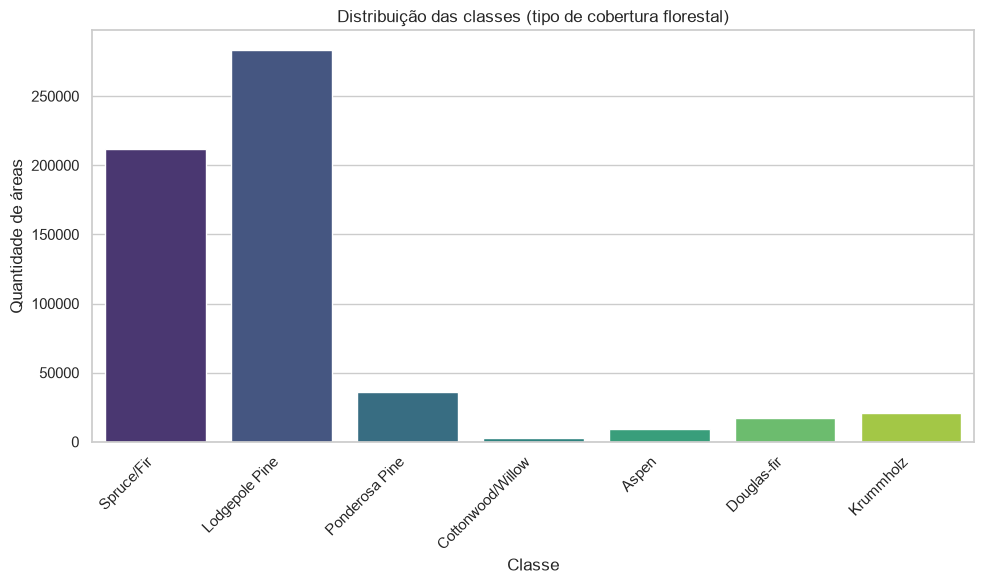

In [5]:
nomes_classes = {
    1: 'Spruce/Fir',
    2: 'Lodgepole Pine',
    3: 'Ponderosa Pine',
    4: 'Cottonwood/Willow',
    5: 'Aspen',
    6: 'Douglas-fir',
    7: 'Krummholz',
}

contagem = df['Cover_Type'].value_counts().sort_index()
tabela = pd.DataFrame({
    'Classe': [nomes_classes[c] for c in contagem.index],
    'Quantidade': contagem.values,
    'Porcentagem': (contagem.values / len(df) * 100).round(2),
}, index=contagem.index)
display(tabela)

plt.figure(figsize=(10, 6))
sns.barplot(x=tabela['Classe'], y=tabela['Quantidade'], hue=tabela['Classe'], palette='viridis', legend=False)
plt.title('Distribuição das classes (tipo de cobertura florestal)')
plt.xlabel('Classe')
plt.ylabel('Quantidade de áreas')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### 4.1 Amostra para os treinos ficarem rápidos

A base completa tem mais de 500 mil linhas, o que deixa alguns modelos (principalmente KNN e as curvas de aprendizado) muito lentos. Usamos uma amostra de 40 mil linhas sorteada de forma estratificada, ou seja, cada classe mantém a mesma proporção que tem na base original.

In [6]:
TAMANHO_AMOSTRA = 40000

df_amostra, _ = train_test_split(df, train_size=TAMANHO_AMOSTRA, stratify=df['Cover_Type'], random_state=SEED)

X = df_amostra.drop(columns='Cover_Type')
y = df_amostra['Cover_Type']

print(f"Amostra: {X.shape[0]} linhas e {X.shape[1]} características")
print("\nProporção das classes na amostra (%):")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

Amostra: 40000 linhas e 54 características

Proporção das classes na amostra (%):
Cover_Type
1    36.46
2    48.76
3     6.15
4     0.47
5     1.64
6     2.99
7     3.53
Name: proportion, dtype: float64


## 5. Divisão em treino e teste

Separamos 80% das linhas para treinar e 20% para testar. O conjunto de teste fica guardado e só é usado para avaliar os modelos no final. Assim medimos como o modelo se comporta com dados que ele nunca viu. A divisão também é estratificada, para treino e teste terem as mesmas proporções de classe.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print(f"Treino: {X_train.shape[0]} linhas")
print(f"Teste:  {X_test.shape[0]} linhas")

proporcoes = pd.DataFrame({
    'Treino (%)': y_train.value_counts(normalize=True).sort_index() * 100,
    'Teste (%)': y_test.value_counts(normalize=True).sort_index() * 100,
}).round(2)
display(proporcoes)

Treino: 32000 linhas
Teste:  8000 linhas


,Treino (%),Teste (%)
Cover_Type,,
1,36.46,36.46
2,48.76,48.76
3,6.15,6.15
4,0.47,0.48
5,1.63,1.64
6,2.99,2.99
7,3.53,3.52


## 6. Pré-processamento e modelos

As 10 primeiras colunas são medidas em escalas muito diferentes (altitude em metros, distâncias, sombreamento de 0 a 255). Modelos como Regressão Logística, KNN e PCA são sensíveis à escala, então padronizamos essas 10 colunas (média 0 e desvio 1). As outras 44 colunas são indicadoras de 0 ou 1 (área silvestre e tipo de solo) e ficam como estão.

Tudo é montado em um `Pipeline`, que junta o pré-processamento e o modelo. Isso evita um erro comum: o padronizador (e depois o PCA) aprende apenas com os dados de treino e só aplica o que aprendeu no teste, sem "espiar" o teste.

Os quatro modelos comparados:

- **Regressão Logística:** modelo linear simples, serve de referência.
- **KNN (k=5):** classifica pela maioria dos 5 vizinhos mais próximos.
- **Árvore de Decisão:** sequência de perguntas sobre as características, com profundidade máxima limitada para não decorar o treino.
- **Random Forest:** muitas árvores votando juntas, também com profundidade máxima limitada.

In [8]:
colunas_numericas = list(X.columns[:10])
print("Colunas padronizadas:", colunas_numericas)


def criar_preprocessador():
    return ColumnTransformer([('num', StandardScaler(), colunas_numericas)], remainder='passthrough')


def criar_modelos(com_pca=False, n_componentes=None):
    modelos = {
        'Regressão Logística': LogisticRegression(max_iter=1000, random_state=SEED),
        'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
        'Árvore de Decisão': DecisionTreeClassifier(max_depth=PROFUNDIDADE_ARVORE, random_state=SEED),
        'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=PROFUNDIDADE_FLORESTA, random_state=SEED, n_jobs=-1),
    }
    pipelines = {}
    for nome, modelo in modelos.items():
        etapas = [('prep', criar_preprocessador())]
        if com_pca:
            etapas.append(('pca', PCA(n_components=n_componentes, random_state=SEED)))
        etapas.append(('modelo', modelo))
        pipelines[nome] = Pipeline(etapas)
    return pipelines


def avaliar(pipelines, X_tr, X_te, y_tr, y_te):
    # Treina cada modelo e calcula as MESMAS métricas para todos, no conjunto de teste
    linhas = []
    previsoes = {}
    for nome, pipe in pipelines.items():
        inicio = time.time()
        pipe.fit(X_tr, y_tr)
        tempo = time.time() - inicio

        pred_treino = pipe.predict(X_tr)
        pred_teste = pipe.predict(X_te)
        previsoes[nome] = pred_teste

        linhas.append({
            'Modelo': nome,
            'Acurácia treino': accuracy_score(y_tr, pred_treino),
            'Acurácia teste': accuracy_score(y_te, pred_teste),
            'Precisão (macro)': precision_score(y_te, pred_teste, average='macro', zero_division=0),
            'Recall (macro)': recall_score(y_te, pred_teste, average='macro', zero_division=0),
            'F1 (macro)': f1_score(y_te, pred_teste, average='macro', zero_division=0),
            'Tempo de treino (s)': tempo,
        })
    return pd.DataFrame(linhas).set_index('Modelo'), previsoes

Colunas padronizadas: ['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points']


## 7. Treino e avaliação dos modelos

Métricas usadas, sempre no conjunto de teste:

- **Acurácia:** porcentagem de acertos no total.
- **Precisão (macro):** das áreas que o modelo apontou como uma classe, quantas realmente eram dela. "Macro" significa que calculamos por classe e tiramos a média simples, então as classes pequenas pesam igual às grandes.
- **Recall (macro):** de todas as áreas que realmente eram de uma classe, quantas o modelo encontrou (também com média simples entre as classes).
- **F1 (macro):** média entre precisão e recall. É a métrica principal para escolher o melhor modelo, justamente porque as classes têm tamanhos diferentes.

A acurácia de treino também aparece na tabela, só para comparar com a de teste mais adiante.

In [9]:
modelos = criar_modelos()
resultados, previsoes = avaliar(modelos, X_train, X_test, y_train, y_test)
display(resultados.round(4))

melhor_modelo = resultados['F1 (macro)'].idxmax()
print(f"\nMelhor modelo pelo F1 macro: {melhor_modelo}")

NameError: name 'PROFUNDIDADE_ARVORE' is not defined

### 7.1 Gráfico comparativo

In [ ]:
metricas_grafico = ['Acurácia teste', 'Precisão (macro)', 'Recall (macro)', 'F1 (macro)']
resultados[metricas_grafico].plot(kind='bar', figsize=(12, 6), colormap='viridis')
plt.title('Comparação dos modelos no conjunto de teste')
plt.ylabel('Valor da métrica')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### 7.2 Matriz de confusão e relatório por classe do melhor modelo

Na matriz de confusão, cada linha é a classe verdadeira e cada coluna é a classe prevista. Os valores estão em proporção por linha, então a diagonal mostra o recall de cada classe. Quanto mais forte a diagonal, melhor. Os valores fora da diagonal mostram quais classes o modelo confunde.

In [ ]:
classes_ordenadas = sorted(y.unique())
nomes_ordenados = [nomes_classes[c] for c in classes_ordenadas]

cm = confusion_matrix(y_test, previsoes[melhor_modelo], labels=classes_ordenadas, normalize='true')
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=nomes_ordenados).plot(
    ax=ax, cmap='Blues', xticks_rotation=45, values_format='.2f', colorbar=False
)
ax.set_title(f'Matriz de confusão normalizada: {melhor_modelo}')
plt.tight_layout()
plt.show()

print(classification_report(y_test, previsoes[melhor_modelo], labels=classes_ordenadas,
                            target_names=nomes_ordenados, zero_division=0))

## 8. Overfitting e underfitting

- **Overfitting:** o modelo decora o treino. Vai muito bem nos dados de treino e pior nos dados novos.
- **Underfitting:** o modelo é simples demais e erra até no treino.

Vamos olhar isso de quatro formas: comparando treino e teste, usando validação cruzada, desenhando curvas de aprendizado e variando a complexidade da árvore.

### 8.1 Comparação entre treino e teste

Usamos como referência (escolha nossa, não uma regra fixa): diferença maior que 5 pontos percentuais entre treino e teste indica overfitting, e acurácia de treino abaixo de 75% indica underfitting. No KNN, a acurácia de treino é inflada porque cada ponto do treino é vizinho de si mesmo. Árvore e Random Forest sem limite de profundidade chegam a 100% no treino porque decoram os dados, por isso limitamos a profundidade delas.

In [ ]:
def diagnosticar(tabela_resultados):
    for nome, linha in tabela_resultados.iterrows():
        diferenca = linha['Acurácia treino'] - linha['Acurácia teste']
        if diferenca > 0.05:
            texto = 'sinal de overfitting (vai bem no treino e pior no teste)'
        elif linha['Acurácia treino'] < 0.75:
            texto = 'sinal de underfitting (erra bastante até no treino)'
        else:
            texto = 'sem sinal forte de overfitting ou underfitting'
        print(f"{nome}: treino {linha['Acurácia treino']:.3f} | teste {linha['Acurácia teste']:.3f} | diferença {diferenca:.3f} -> {texto}")


diagnosticar(resultados)

resultados[['Acurácia treino', 'Acurácia teste']].plot(kind='bar', figsize=(10, 6), color=['#4c72b0', '#dd8452'])
plt.title('Acurácia no treino e no teste')
plt.ylabel('Acurácia')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 8.2 Validação cruzada

Em vez de confiar em uma única divisão, a validação cruzada divide o treino em 5 partes. Cada parte é usada uma vez como validação enquanto as outras 4 treinam o modelo. Assim temos 5 notas por modelo. A média mostra o desempenho esperado e o desvio padrão mostra a estabilidade. O conjunto de teste não é usado aqui.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

linhas_cv = []
for nome, pipe in criar_modelos().items():
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['accuracy', 'f1_macro'],
                       return_train_score=True, n_jobs=1)
    linhas_cv.append({
        'Modelo': nome,
        'Acurácia treino (média)': r['train_accuracy'].mean(),
        'Acurácia validação (média)': r['test_accuracy'].mean(),
        'Acurácia validação (desvio)': r['test_accuracy'].std(),
        'F1 macro validação (média)': r['test_f1_macro'].mean(),
        'F1 macro validação (desvio)': r['test_f1_macro'].std(),
    })

resultados_cv = pd.DataFrame(linhas_cv).set_index('Modelo')
display(resultados_cv.round(4))

resultados_cv[['Acurácia treino (média)', 'Acurácia validação (média)']].plot(
    kind='bar', figsize=(10, 6), color=['#4c72b0', '#dd8452'])
plt.title('Validação cruzada (5 partes): treino e validação')
plt.ylabel('Acurácia')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 8.3 Curvas de aprendizado

Cada gráfico mostra a acurácia conforme aumentamos a quantidade de dados de treino. A linha azul é o treino e a laranja é a validação (cada ponto usa validação cruzada com 3 partes). Como interpretar:

- Duas linhas juntas e baixas: underfitting.
- Linha azul no alto e laranja bem abaixo, com espaço grande entre elas: overfitting.
- Linha laranja ainda subindo no final: mais dados provavelmente ajudariam.

Esta célula é a mais demorada do notebook.

In [ ]:
fig, eixos = plt.subplots(2, 2, figsize=(14, 10))
eixos = eixos.flatten()

for eixo, (nome, pipe) in zip(eixos, criar_modelos().items()):
    tamanhos, notas_treino, notas_val = learning_curve(
        pipe, X_train, y_train, train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0],
        cv=3, scoring='accuracy', n_jobs=1, shuffle=True, random_state=SEED
    )
    media_tr, desvio_tr = notas_treino.mean(axis=1), notas_treino.std(axis=1)
    media_va, desvio_va = notas_val.mean(axis=1), notas_val.std(axis=1)

    eixo.plot(tamanhos, media_tr, 'o-', label='Treino', color='#4c72b0')
    eixo.fill_between(tamanhos, media_tr - desvio_tr, media_tr + desvio_tr, alpha=0.15, color='#4c72b0')
    eixo.plot(tamanhos, media_va, 'o-', label='Validação', color='#dd8452')
    eixo.fill_between(tamanhos, media_va - desvio_va, media_va + desvio_va, alpha=0.15, color='#dd8452')
    eixo.set_title(nome)
    eixo.set_xlabel('Quantidade de dados de treino')
    eixo.set_ylabel('Acurácia')
    eixo.set_ylim(0.4, 1.02)
    eixo.legend(loc='lower right')

plt.suptitle('Curvas de aprendizado', fontsize=14)
plt.tight_layout()
plt.show()

### 8.4 Complexidade da Árvore de Decisão

Uma árvore sem limite de profundidade cresce até decorar o treino (100% de acerto no treino), por isso nos modelos da seção 6 já limitamos a profundidade da árvore e da Random Forest. Aqui testamos várias profundidades máximas (`max_depth`) com validação cruzada dentro do treino. Profundidade baixa tende a underfitting e profundidade alta tende a overfitting. Escolhemos a profundidade com a melhor nota de validação e só depois olhamos o resultado no teste.

In [ ]:
profundidades = [2, 4, 6, 8, 10, 12, 15, 20, 25, 30]

arvore_pipe = criar_modelos()['Árvore de Decisão']
notas_treino, notas_val = validation_curve(
    arvore_pipe, X_train, y_train, param_name='modelo__max_depth', param_range=profundidades,
    cv=cv, scoring='accuracy', n_jobs=-1
)

media_tr = notas_treino.mean(axis=1)
media_va = notas_val.mean(axis=1)

plt.figure(figsize=(10, 6))
plt.plot(profundidades, media_tr, 'o-', label='Treino', color='#4c72b0')
plt.plot(profundidades, media_va, 'o-', label='Validação', color='#dd8452')
plt.title('Acurácia da Árvore de Decisão conforme a profundidade máxima')
plt.xlabel('Profundidade máxima (max_depth)')
plt.ylabel('Acurácia')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

melhor_profundidade = profundidades[int(np.argmax(media_va))]
print(f"Melhor profundidade na validação cruzada: {melhor_profundidade} (acurácia de validação {media_va.max():.4f})")

Agora treinamos a árvore com a profundidade escolhida e comparamos com a árvore da seção 7 (profundidade fixada em PROFUNDIDADE_ARVORE), no teste.

In [ ]:
arvore_ajustada = {
    f'Árvore (max_depth={melhor_profundidade})': Pipeline([
        ('prep', criar_preprocessador()),
        ('modelo', DecisionTreeClassifier(max_depth=melhor_profundidade, random_state=SEED)),
    ])
}
res_ajustada, prev_ajustada = avaliar(arvore_ajustada, X_train, X_test, y_train, y_test)

comparacao_arvores = pd.concat([resultados.loc[['Árvore de Decisão']], res_ajustada])
display(comparacao_arvores.round(4))
diagnosticar(comparacao_arvores)

## 9. Redução de dimensionalidade com PCA

A base tem 54 características. O PCA (Análise de Componentes Principais) cria novas variáveis, chamadas componentes, que misturam as originais e são ordenadas pela quantidade de informação (variância) que guardam. Ficando só com os primeiros componentes, usamos menos variáveis e perdemos pouca informação.

O PCA é ajustado apenas com os dados de treino, dentro do `Pipeline`, depois da padronização das 10 colunas numéricas.

### 9.1 Quantos componentes são necessários?

O gráfico da esquerda mostra a variância que cada componente explica. O da direita mostra a variância acumulada. Vamos escolher o menor número de componentes que guarda pelo menos 95% da informação.

In [ ]:
pca_completo = Pipeline([('prep', criar_preprocessador()), ('pca', PCA(random_state=SEED))])
pca_completo.fit(X_train)

variancia = pca_completo.named_steps['pca'].explained_variance_ratio_
acumulada = np.cumsum(variancia)
n_componentes_95 = int(np.argmax(acumulada >= 0.95)) + 1

print(f"Características originais: {X_train.shape[1]}")
print(f"Componentes necessários para guardar 95% da variância: {n_componentes_95}")

fig, eixos = plt.subplots(1, 2, figsize=(15, 5))

eixos[0].bar(range(1, 21), variancia[:20], color='steelblue')
eixos[0].set_title('Variância explicada pelos 20 primeiros componentes')
eixos[0].set_xlabel('Componente')
eixos[0].set_ylabel('Proporção da variância')

eixos[1].plot(range(1, len(acumulada) + 1), acumulada, 'o-', markersize=3)
eixos[1].axhline(0.95, color='red', linestyle='--', label='95%')
eixos[1].axvline(n_componentes_95, color='green', linestyle='--', label=f'{n_componentes_95} componentes')
eixos[1].set_title('Variância acumulada')
eixos[1].set_xlabel('Número de componentes')
eixos[1].set_ylabel('Variância acumulada')
eixos[1].legend()

plt.tight_layout()
plt.show()

### 9.2 Visualização das classes em 2 dimensões

Projetamos 5 mil pontos do treino nos 2 primeiros componentes só para enxergar a base. Duas dimensões guardam pouca informação, então é normal que as classes apareçam misturadas. O gráfico serve para ter uma ideia da separação, não para medir a qualidade do modelo.

In [ ]:
rng = np.random.RandomState(SEED)
indices = rng.choice(len(X_train), size=5000, replace=False)
pontos = pca_completo.transform(X_train.iloc[indices])[:, :2]
rotulos = y_train.iloc[indices].map(nomes_classes)

plt.figure(figsize=(10, 7))
sns.scatterplot(x=pontos[:, 0], y=pontos[:, 1], hue=rotulos, hue_order=nomes_ordenados,
                palette='tab10', alpha=0.6, s=18)
plt.title('Áreas projetadas nos 2 primeiros componentes do PCA')
plt.xlabel('Componente 1')
plt.ylabel('Componente 2')
plt.legend(title='Classe', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 9.3 Modelos treinados com PCA

Treinamos os mesmos quatro modelos, com a mesma divisão e as mesmas métricas, agora usando apenas os componentes escolhidos.

In [ ]:
modelos_pca = criar_modelos(com_pca=True, n_componentes=n_componentes_95)
resultados_pca, previsoes_pca = avaliar(modelos_pca, X_train, X_test, y_train, y_test)
display(resultados_pca.round(4))
diagnosticar(resultados_pca)

### 9.4 Comparação com e sem PCA

Aqui vemos o que o PCA mudou na qualidade (acurácia e F1 no teste) e no tempo de treino.

In [ ]:
comparacao_pca = pd.DataFrame({
    'Acurácia teste (sem PCA)': resultados['Acurácia teste'],
    'Acurácia teste (com PCA)': resultados_pca['Acurácia teste'],
    'F1 macro (sem PCA)': resultados['F1 (macro)'],
    'F1 macro (com PCA)': resultados_pca['F1 (macro)'],
    'Tempo em s (sem PCA)': resultados['Tempo de treino (s)'],
    'Tempo em s (com PCA)': resultados_pca['Tempo de treino (s)'],
})
display(comparacao_pca.round(4))

fig, eixos = plt.subplots(1, 2, figsize=(15, 6))

comparacao_pca[['F1 macro (sem PCA)', 'F1 macro (com PCA)']].plot(
    kind='bar', ax=eixos[0], color=['#4c72b0', '#55a868'])
eixos[0].set_title('F1 macro no teste')
eixos[0].set_ylabel('F1 macro')
eixos[0].set_ylim(0, 1)
eixos[0].tick_params(axis='x', rotation=0)

comparacao_pca[['Tempo em s (sem PCA)', 'Tempo em s (com PCA)']].plot(
    kind='bar', ax=eixos[1], color=['#4c72b0', '#55a868'])
eixos[1].set_title('Tempo de treino')
eixos[1].set_ylabel('Segundos')
eixos[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

## 10. Conclusões

Os números abaixo são calculados direto dos resultados acima, para o texto sempre acompanhar os dados.

In [ ]:
print(f"Base usada: {df.shape[0]} linhas na base original, amostra de {len(X)} linhas "
      f"({len(X_train)} para treino e {len(X_test)} para teste)")

print()
print("Ranking dos modelos pelo F1 macro no teste (sem PCA):")
for posicao, (nome, linha) in enumerate(resultados.sort_values('F1 (macro)', ascending=False).iterrows(), start=1):
    print(f"  {posicao}. {nome}: F1 macro {linha['F1 (macro)']:.3f} | acurácia {linha['Acurácia teste']:.3f}")

print()
cv_melhor = resultados_cv.loc[melhor_modelo]
print(f"Melhor modelo: {melhor_modelo}")
print(f"  Acurácia no teste: {resultados.loc[melhor_modelo, 'Acurácia teste']:.3f}")
print(f"  Acurácia média na validação cruzada: {cv_melhor['Acurácia validação (média)']:.3f} "
      f"(desvio {cv_melhor['Acurácia validação (desvio)']:.3f})")

print()
print("Overfitting e underfitting:")
diagnosticar(resultados)
nome_ajustada = res_ajustada.index[0]
print(f"A árvore limitada a max_depth={melhor_profundidade} ficou com diferença treino-teste de "
      f"{res_ajustada.loc[nome_ajustada, 'Acurácia treino'] - res_ajustada.loc[nome_ajustada, 'Acurácia teste']:.3f}, "
      f"contra {resultados.loc['Árvore de Decisão', 'Acurácia treino'] - resultados.loc['Árvore de Decisão', 'Acurácia teste']:.3f} "
      f"da árvore da seção 7 (max_depth={PROFUNDIDADE_ARVORE}).")

print()
print(f"PCA: {n_componentes_95} componentes guardam 95% da variância (de {X_train.shape[1]} características).")
dif_f1 = resultados_pca.loc[melhor_modelo, 'F1 (macro)'] - resultados.loc[melhor_modelo, 'F1 (macro)']
dif_tempo = resultados_pca.loc[melhor_modelo, 'Tempo de treino (s)'] - resultados.loc[melhor_modelo, 'Tempo de treino (s)']
print(f"  No {melhor_modelo}, o F1 macro mudou {dif_f1:+.3f} e o tempo de treino mudou {dif_tempo:+.1f} s com o PCA.")
melhor_com_pca = resultados_pca['F1 (macro)'].idxmax()
print(f"  Melhor modelo com PCA: {melhor_com_pca} (F1 macro {resultados_pca.loc[melhor_com_pca, 'F1 (macro)']:.3f})")

### Limitações

- Usamos uma amostra de 40 mil linhas da base de mais de 500 mil. Com a base completa os resultados podem melhorar, principalmente para os modelos mais flexíveis, como a Random Forest.
- Os modelos usaram os parâmetros padrão do scikit-learn, com duas exceções: a profundidade máxima da Árvore de Decisão e da Random Forest foi limitada (sem limite, elas chegam a 100% de acerto no treino porque decoram os dados) e a profundidade da seção 8.4 foi escolhida por validação cruzada. Os limites da seção 6 foram escolhidos por nós. Um ajuste mais amplo de parâmetros poderia melhorar os resultados.
- As classes têm tamanhos bem diferentes. Por isso usamos o F1 macro como métrica principal e olhamos a matriz de confusão, mas as classes menores continuam sendo as mais difíceis de acertar.
- O PCA é uma técnica linear e aqui foi aplicado junto com variáveis indicadoras (0 ou 1), o que limita o quanto ele consegue comprimir a base sem perder informação.
- Os limites usados para sinalizar overfitting (5 pontos percentuais) e underfitting (75%) são referências escolhidas por nós, não regras absolutas.